# Model playground

A shared harness for trying models on the bioreactor task. Every model is scored the same way:

- **Task:** predict `vcd`, `tcd`, `substrate`, `byproduct` at the daily samples from day 1 to day 13 of a batch.
- **Allowed inputs:** what a test batch gives you: the **day-0 sample**, all **feed events**, and **volume**.
- **Validation:** 5-fold cross-validation **by batch** on the 49 training batches, stratified by feeding identifier.
- **Score:** MAPE per variable and their mean (the competition metric).

The first real model is a **mechanistic ODE (mass balance) model whose parameters are fitted with
`scipy.optimize.least_squares`**, with optional **basin hopping** to escape local minima.

### Are these the right inputs?

Mostly yes. Two adjustments make least squares work well here:

1. **Add the day-0 state.** Each batch's starting `vcd`, `tcd`, `substrate` and `byproduct` explain a lot of where it
   ends up, and test batches provide them. Without them every batch with the same feeds gets the same prediction.
2. **Use least squares to fit a dynamic model, not a static regression.** A regression `y ~ f(time, feeds, volume)`
   can't express that a feed on day 5 affects day 6 onwards, or that dilution depends on the current volume.
   An ODE that is integrated through the feed events gets this right by construction. Least squares then
   fits about 14 shared kinetic parameters to about 2,000 data points. That is well-determined and hard to overfit.

**What the inputs physically are:** the feed columns are **volumes** added to the reactor. The measured volume equals
the starting volume plus cumulative feed volume (r = 0.9999), minus a small sampling loss. So each feed dilutes the culture,
and `feed_b` / `feed_substrate` also carry substrate (their concentrations are fitted). `time` enters through the
integration, and `volume` through dilution at each feed. `feed_c` and `feed_d` are used as volume only, because what they contain is unknown.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import least_squares, basinhopping, OptimizeResult
from sklearn.model_selection import StratifiedKFold

DATA = Path("../data")
raw = pd.read_csv(DATA / "bioreaction_remaining.csv").sort_values(["batch_id", "elapsed_time"]).reset_index(drop=True)
template = pd.read_csv(DATA / "bioreaction_template.csv")

STATE = ["vcd", "tcd", "substrate", "byproduct"]
FEEDS = ["feed_b", "feed_substrate", "feed_c", "feed_d"]      # order matters for the ODE model below
VAR_COLORS = dict(zip(STATE, ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]))
sns.set_theme(style="whitegrid", rc={"grid.color": "#e6e5e1", "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold",
                                     "axes.titlesize": 11, "figure.dpi": 110, "lines.linewidth": 2})

TEST_IDS = sorted(raw.loc[raw.to_predict, "batch_id"].unique(), key=lambda b: int(b[5:]))
TRAIN_IDS = sorted(set(raw.batch_id) - set(TEST_IDS), key=lambda b: int(b[5:]))

# Rows to score: every measured daily sample after day 0 (exactly what the template asks for in test batches)
TARGETS = raw[raw.batch_id.isin(TRAIN_IDS) & raw.vcd.notna() & (raw.elapsed_time > 0.5)][["batch_id", "elapsed_time"] + STATE]
print(f"{len(TRAIN_IDS)} train batches, {len(TEST_IDS)} test batches, {len(TARGETS)} scored train samples")

49 train batches, 12 test batches, 637 scored train samples


## 1. Validation harness

**Folds:** the team's agreed 5-fold split by batch (`TEAM_FOLDS`), so scores are comparable across everyone's notebooks.
Each fold holds out 9-10 batches and trains on the other 39-40, which mirrors the real 49 / 12 split.
`make_folds()` is kept for repeated, stratified folds if you want a more stable estimate later.

The **feeding identifier** (from `data_overview.ipynb`, section 5b) is used for per-group diagnostics.

In [2]:
def feeding_identifier(df):
    out = {}
    for bid, g in df.dropna(subset=["feed_substrate"]).groupby("batch_id"):
        early = (g.elapsed_time < 11).any()
        late = g[g.elapsed_time >= 11].sort_values("elapsed_time").feed_substrate.values
        out[bid] = ("early" if early else "none") + "·" + "".join("H" if v > 0.08 else "L" for v in late[:2])
    return pd.Series(out, name="regimen")

REGIMEN = feeding_identifier(raw)

def make_folds(n_splits=5, n_repeats=1, seed=0):
    ids = np.array(TRAIN_IDS)
    folds = []
    for r in range(n_repeats):
        skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed + r)
        for tr, va in skf.split(ids, REGIMEN.loc[ids]):
            folds.append((list(ids[tr]), list(ids[va])))
    return folds

# Team split: batches held out in each fold
TEAM_HOLDOUT = {
    1: ["Batch8", "Batch25", "Batch28", "Batch30", "Batch36", "Batch39", "Batch42", "Batch46", "Batch58", "Batch61"],
    2: ["Batch7", "Batch10", "Batch13", "Batch21", "Batch22", "Batch33", "Batch45", "Batch47", "Batch53", "Batch55"],
    3: ["Batch4", "Batch19", "Batch20", "Batch26", "Batch29", "Batch34", "Batch38", "Batch49", "Batch50", "Batch52"],
    4: ["Batch1", "Batch9", "Batch14", "Batch15", "Batch23", "Batch27", "Batch31", "Batch37", "Batch43", "Batch51"],
    5: ["Batch2", "Batch3", "Batch11", "Batch16", "Batch17", "Batch18", "Batch41", "Batch44", "Batch59"],
}
held = [b for v in TEAM_HOLDOUT.values() for b in v]
assert sorted(held) == sorted(TRAIN_IDS), "team folds must cover each training batch exactly once"
TEAM_FOLDS = [([b for b in TRAIN_IDS if b not in va], va) for va in TEAM_HOLDOUT.values()]

FOLDS = TEAM_FOLDS          # or: make_folds(n_repeats=3) for repeated stratified folds
pd.DataFrame({"fold": list(TEAM_HOLDOUT), "n_val": [len(v) for v in TEAM_HOLDOUT.values()],
              "feeding identifiers held out": [", ".join(f"{k}×{n}" for k, n in REGIMEN.loc[v].value_counts().items())
                                               for v in TEAM_HOLDOUT.values()]}).set_index("fold")

,n_val,feeding identifiers held out
fold,,
1,10,"none·HL×4, early·HL×2, none·LL×2, none·LH×1, n..."
2,10,"none·HL×6, early·LL×2, none·HH×1, none·LH×1"
3,10,"none·HL×6, none·LL×3, early·LL×1"
4,10,"none·HL×8, none·LH×2"
5,9,"none·LL×3, none·HL×2, none·LH×1, none·HH×1, ea..."


**The model interface.** Any model is a class with two methods:

```python
class MyModel:
    def fit(self, batch_ids): ...                  # may use all rows of these (training) batches
    def predict(self, batch_ids, query): ...        # query = DataFrame[batch_id, elapsed_time]
                                                    # may only use day-0 sample, feeds and volume of batch_ids
                                                    # returns DataFrame[STATE] aligned with query rows
```

`cross_validate(MyModel, name)` runs it over the folds and stores the scores in `RESULTS` for comparison.

In [3]:
def mape(pred, true):
    return float(np.mean(np.abs(pred - true) / np.abs(true)) * 100)

def score(pred, truth):
    s = {v: mape(pred[v].values, truth[v].values) for v in STATE}
    s["mean"] = float(np.mean(list(s.values())))
    return s

RESULTS, OOF, MODELS, SPECS = {}, {}, {}, {}   # per-fold scores, out-of-fold predictions, fold models, how to rebuild

def cross_validate(model_cls, name, folds=FOLDS, **kwargs):
    t0, rows, oof, models = time.time(), [], [], []
    for k, (tr, va) in enumerate(folds):
        model = model_cls(**kwargs)
        model.fit(tr)
        models.append(model)
        truth = TARGETS[TARGETS.batch_id.isin(va)].reset_index(drop=True)
        pred = model.predict(va, truth[["batch_id", "elapsed_time"]]).reset_index(drop=True)
        rows.append({"fold": k, **score(pred, truth)})
        oof.append(truth[["batch_id", "elapsed_time"]].assign(**{f"{v}_pred": pred[v] for v in STATE},
                                                               **{v: truth[v] for v in STATE}, fold=k))
    RESULTS[name] = pd.DataFrame(rows)
    OOF[name] = pd.concat(oof, ignore_index=True)
    MODELS[name] = models
    SPECS[name] = (model_cls, kwargs)
    summary = RESULTS[name][STATE + ["mean"]].agg(["mean", "std"]).round(2)
    print(f"{name}: {time.time() - t0:.0f}s")
    return summary

## 2. Baseline: median trajectory scaled by day 0

For each variable and day, take the median ratio `y(day) / y(day 0)` over the training batches, then multiply it by
the batch's own day-0 value. Any real model has to beat this.

In [4]:
def day0_sample(batch_ids):
    d0 = raw[raw.batch_id.isin(batch_ids) & raw.vcd.notna() & (raw.elapsed_time < 0.05)]
    return d0.set_index("batch_id")[STATE + ["volume"]]

class MedianRatioBaseline:
    def fit(self, batch_ids):
        s = raw[raw.batch_id.isin(batch_ids) & raw.vcd.notna()].copy()
        s["day"] = s.elapsed_time.round().astype(int)
        s = s.join(day0_sample(batch_ids)[STATE], on="batch_id", rsuffix="_0")
        for v in STATE:
            s[v + "_ratio"] = s[v] / s[v + "_0"]
        self.ratio = s.groupby("day")[[v + "_ratio" for v in STATE]].median()
        return self

    def predict(self, batch_ids, query):
        day = query.elapsed_time.round().astype(int).clip(upper=self.ratio.index.max())
        r = self.ratio.loc[day].reset_index(drop=True)
        d0 = day0_sample(batch_ids).loc[query.batch_id, STATE].reset_index(drop=True)
        return pd.DataFrame({v: d0[v] * r[v + "_ratio"] for v in STATE})

cross_validate(MedianRatioBaseline, "baseline: median ratio")

baseline: median ratio: 0s


,vcd,tcd,substrate,byproduct,mean
mean,8.33,8.23,11.54,13.22,10.33
std,1.71,1.78,2.67,1.07,0.99


## 3. ODE mass-balance model fitted with least squares

**States** (concentrations): viable cells $X_v$, dead cells $X_d$ (so `tcd` = $X_v + X_d$), substrate $S$, byproduct $P$.

**Between feeds:**

$$
\begin{aligned}
\mu &= \mu_{max}\,\frac{S}{K_s + S}\,\frac{1}{1 + (X_v/X_{max})^4} &&\text{growth, limited by substrate and density}\\
k_d &= k_{d0} + k_{d1}\,\frac{K_{ds}}{K_{ds} + S} &&\text{death, rises when substrate runs low}\\
\dot X_v &= (\mu - k_d)\,X_v \qquad \dot X_d = k_d X_v - k_{lys} X_d\\
\dot S &= -\Big(\frac{\mu}{Y_{xs}} + m_s \frac{S}{S + 0.1}\Big) X_v\\
\dot P &= \Big(Y_{px}\,\mu - q_c \frac{P}{K_c + P}\Big) X_v &&\text{made during growth, consumed later}
\end{aligned}
$$

**At each feed event** of volume $f$: all concentrations are diluted by $V/(V+f)$. `feed_b` and `feed_substrate`
also add substrate at fitted concentrations $S_{feed,b}$, $S_{feed,sub}$.

**Fitting:** the 14 parameters are shared by all batches and fitted in log space (keeps them positive and puts
them on one scale). Each batch starts from its own measured day-0 state. Residuals are **relative errors** `(pred - obs) / obs`,
so the objective lines up with MAPE. `soft_l1` loss makes it behave like absolute rather than squared error for larger misses.

**Basin hopping** (optional) repeatedly perturbs the best parameters and re-runs `least_squares` from there, keeping
the best fit. That helps when the fit lands in a local minimum.

The simulator integrates all batches at once with a vectorized RK4 on a 0.05-day grid (~20 ms per simulation).

In [5]:
DT = 0.05
GRID = np.arange(0, 13.1 + DT, DT)

PARAMS = pd.DataFrame([
    # name,        initial guess, lower, upper
    ("mu_max",      0.8,   0.05,   20),
    ("Ks",          0.5,   0.005,  50),
    ("Xmax",       35.0,   5.0,   200),
    ("kd0",         0.03,  1e-4,   2),
    ("kd1",         0.1,   1e-4,   5),
    ("Kds",         0.5,   0.005,  50),
    ("klys",        0.05,  1e-4,   5),
    ("Yxs",         2.0,   0.05,  100),
    ("ms",          0.02,  1e-4,   2),
    ("Ypx",         0.4,   1e-3,   10),
    ("qc",          0.03,  1e-4,   5),
    ("Kc",          0.5,   0.005,  50),
    ("S_feed_b",   15.0,   0.1,   500),
    ("S_feed_sub", 100.0,  1.0,  2000),
], columns=["name", "init", "lower", "upper"]).set_index("name")
LOG_INIT, LOG_LB, LOG_UB = (np.log(PARAMS[c].values) for c in ["init", "lower", "upper"])


def build_inputs(batch_ids):
    """Per-batch day-0 state, start volume, and feed volumes binned onto the time grid."""
    B, T = len(batch_ids), len(GRID)
    feed = np.zeros((len(FEEDS), B, T))
    d0 = day0_sample(batch_ids).loc[batch_ids]
    x0 = np.vstack([d0.vcd, d0.tcd - d0.vcd, d0.substrate, d0.byproduct]).astype(float)
    sub = raw[raw.batch_id.isin(batch_ids)]
    index = {b: i for i, b in enumerate(batch_ids)}
    for k, f in enumerate(FEEDS):
        ev = sub.dropna(subset=[f])
        t_idx = np.minimum(np.ceil(ev.elapsed_time.values / DT).astype(int), T - 1)
        np.add.at(feed[k], (ev.batch_id.map(index).values, t_idx), ev[f].values)
    return {"feed": feed, "x0": x0, "v0": d0.volume.values.astype(float), "index": index}


def rhs(Xv, Xd, S, P, p):
    mu_max, Ks, Xmax, kd0, kd1, Kds, klys, Yxs, ms, Ypx, qc, Kc = p[:12]
    S, P = np.maximum(S, 0), np.maximum(P, 0)
    mu = mu_max * S / (Ks + S) / (1 + (Xv / Xmax) ** 4)
    kd = kd0 + kd1 * Kds / (Kds + S)
    return ((mu - kd) * Xv,
            kd * Xv - klys * Xd,
            -(mu / Yxs + ms * S / (S + 0.1)) * Xv,
            (Ypx * mu - qc * P / (Kc + P)) * Xv)


def simulate(p, inp):
    """Returns array (4 states, batches, grid) of Xv, Xd, S, P."""
    feed, V = inp["feed"], inp["v0"].copy()
    x = list(inp["x0"].copy())
    S_b, S_sub = p[12], p[13]
    out = np.empty((4, V.size, len(GRID)))
    for t in range(len(GRID)):
        fv = feed[:, :, t].sum(0)
        if fv.any():                                     # bolus feed: dilute, add substrate
            Vn = V + fv
            x[0], x[1], x[3] = x[0] * V / Vn, x[1] * V / Vn, x[3] * V / Vn
            x[2] = (x[2] * V + feed[0, :, t] * S_b + feed[1, :, t] * S_sub) / Vn
            V = Vn
        out[:, :, t] = x
        k1 = rhs(*x, p)
        k2 = rhs(*[a + DT / 2 * b for a, b in zip(x, k1)], p)
        k3 = rhs(*[a + DT / 2 * b for a, b in zip(x, k2)], p)
        k4 = rhs(*[a + DT * b for a, b in zip(x, k3)], p)
        x = [a + DT / 6 * (b + 2 * c + 2 * d + e) for a, b, c, d, e in zip(x, k1, k2, k3, k4)]
    return out


def sim_at(p, inp, query):
    """Simulated vcd/tcd/substrate/byproduct at the (batch_id, elapsed_time) rows of query."""
    s = simulate(p, inp)
    b = query.batch_id.map(inp["index"]).values
    t = np.minimum(np.floor(query.elapsed_time.values / DT).astype(int), len(GRID) - 1)   # state just before any feed at that time
    Xv, Xd, S, P = (s[k, b, t] for k in range(4))
    return np.column_stack([Xv, Xv + Xd, S, P])

In [6]:
F_SCALE = 0.1      # soft_l1: relative errors above ~10% are penalised ~linearly (MAPE-like)

def soft_l1_cost(r):
    z = (r / F_SCALE) ** 2
    return 0.5 * F_SCALE ** 2 * np.sum(2 * (np.sqrt(1 + z) - 1))


class ODELeastSquares:
    def __init__(self, bh_niter=0, bh_stepsize=0.7, seed=0, max_nfev=3000, verbose=False):
        self.bh_niter, self.bh_stepsize, self.seed = bh_niter, bh_stepsize, seed
        self.max_nfev, self.verbose = max_nfev, verbose

    def fit(self, batch_ids):
        inp = build_inputs(list(batch_ids))
        obs = TARGETS[TARGETS.batch_id.isin(batch_ids)]
        Y = obs[STATE].values
        resid = lambda lp: ((sim_at(np.exp(lp), inp, obs) - Y) / Y).ravel()

        def local_fit(lp0):
            return least_squares(resid, np.clip(lp0, LOG_LB + 1e-9, LOG_UB - 1e-9), bounds=(LOG_LB, LOG_UB),
                                 loss="soft_l1", f_scale=F_SCALE, x_scale="jac", diff_step=1e-4,
                                 xtol=1e-10, ftol=1e-10, gtol=1e-10, max_nfev=self.max_nfev)

        t0 = time.time()
        best = local_fit(LOG_INIT)
        self.history = [best.cost]
        if self.bh_niter:
            def lsq_minimizer(fun, x0, args=(), **kw):       # plugs least_squares into basinhopping
                r = local_fit(x0)
                self.history.append(r.cost)
                return OptimizeResult(x=r.x, fun=r.cost, success=r.success, nfev=r.nfev)
            bh = basinhopping(lambda lp: soft_l1_cost(resid(lp)), best.x, niter=self.bh_niter,
                              stepsize=self.bh_stepsize, minimizer_kwargs={"method": lsq_minimizer},
                              seed=self.seed)
            lp_best, cost_best = bh.x, bh.fun
        else:
            lp_best, cost_best = best.x, best.cost
        self.log_params, self.cost = lp_best, cost_best
        self.params = pd.Series(np.exp(lp_best), index=PARAMS.index)
        if self.verbose:
            print(f"fit {len(batch_ids)} batches: cost {best.cost:.2f} -> {cost_best:.2f}, {time.time() - t0:.0f}s")
        return self

    def predict(self, batch_ids, query):
        inp = build_inputs(list(batch_ids))
        return pd.DataFrame(sim_at(self.params.values, inp, query), columns=STATE)

### 3a. Plain least squares, cross-validated

In [7]:
cross_validate(ODELeastSquares, "ODE + least squares")

ODE + least squares: 76s


,vcd,tcd,substrate,byproduct,mean
mean,10.79,10.02,17.39,18.15,14.09
std,1.02,0.95,1.94,0.44,0.46


### 3b. Does basin hopping find a better minimum?

Each hop is a full `least_squares` run (~15 s), so basin hopping is slow inside CV. This cell first checks whether it
improves the fit on all 49 batches. Only if the cost drops meaningfully is it worth cross-validating (`BH_IN_CV = True`).

fit 49 batches: cost 21.13 -> 21.13, 17s


fit 49 batches: cost 21.13 -> 21.13, 63s


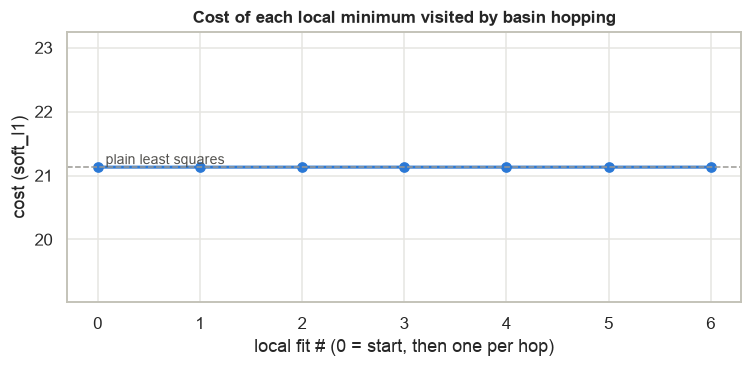

basin hopping changed the cost by -0.0002%


,plain,basin hopping
name,,
mu_max,11.8263,11.8264
Ks,50.0000,50.0000
Xmax,20.7607,20.7608
kd0,0.1549,0.1550
kd1,0.0001,0.0001
Kds,50.0000,0.0050
klys,3.0002,3.0003
Yxs,5.0005,5.0004
ms,0.1199,0.1199


In [8]:
BH_NITER = 5          # number of hops; each costs one local least-squares fit
BH_IN_CV = False      # set True to also cross-validate the basin-hopping version (≈ BH_NITER+1 × slower)

plain = ODELeastSquares(verbose=True).fit(TRAIN_IDS)
hopped = ODELeastSquares(bh_niter=BH_NITER, verbose=True).fit(TRAIN_IDS)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(len(hopped.history)), hopped.history, marker="o", color="#2a78d6")
ax.axhline(plain.cost, color="#9a9893", linestyle="--", linewidth=1)
ax.text(0, plain.cost, "  plain least squares", va="bottom", fontsize=9, color="#52514e")
ax.set_ylim(plain.cost * 0.9, plain.cost * 1.1)                 # ±10% window, so tiny changes look tiny
ax.ticklabel_format(axis="y", useOffset=False)
ax.set_xlabel("local fit # (0 = start, then one per hop)"); ax.set_ylabel("cost (soft_l1)")
ax.set_title("Cost of each local minimum visited by basin hopping")
plt.tight_layout(); plt.show()
print(f"basin hopping changed the cost by {100 * (hopped.cost - plain.cost) / plain.cost:+.4f}%")

pd.DataFrame({"plain": plain.params, "basin hopping": hopped.params}).round(4)

In [9]:
if BH_IN_CV:
    display(cross_validate(ODELeastSquares, f"ODE + LSQ + basin hopping ({BH_NITER})", bh_niter=BH_NITER))

## 3c. Data-driven models: ridge, gradient boosting and their ensemble

All batches follow nearly the same shape, so these models predict each batch's **deviation from its own start**:
the log ratio `log(y_day / y_day0)` for every variable and day 1-13. The prediction is then `y_day0 × exp(log ratio)`.

**Features per batch.** Everything a test batch provides, nothing measured after day 0:

| Group | Features |
|---|---|
| Day-0 sample | log `vcd`, `tcd`, `substrate`, `byproduct` at day 0; start volume |
| `feed_b` | dose on each day 1-12 |
| `feed_c` | number of small doses, total volume |
| `feed_substrate` | early dose yes/no, day of early dose, high dose at day 11.5, high dose at day 12.5 |
| Volume | volume added by each sample day 1-13 |

The `feed_substrate` flags matter because that feed follows a threshold rule (`data_overview` section 5b). A high dose at day
11.5 means substrate was below ~0.96 at day 11, and an early dose means it dipped below ~2.

**Models**

- **Ridge:** one multi-output linear model per variable (13 days at once) on standardised features. The regularisation
  strength is chosen by `RidgeCV` inside each training fold only.
- **Gradient boosting:** `HistGradientBoostingRegressor`, one per variable, in long format (one row per batch and day,
  with `day` as a feature). Shallow trees and fixed settings, not tuned on the validation folds.
- **Ensemble:** geometric mean of the two predictions. The two models make different mistakes, so averaging cancels part of them.

In [10]:
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import StandardScaler

DAYS = list(range(1, 14))

def build_features():
    """One row per batch (all 61), using only inputs that test batches provide."""
    ids = sorted(raw.batch_id.unique(), key=lambda b: int(b[5:]))
    by_day = lambda d: d.assign(day=d.elapsed_time.round().astype(int))
    d0 = day0_sample(ids)
    F = pd.DataFrame(index=ids)
    for v in STATE:
        F[f"log_{v}_d0"] = np.log(d0[v])
    F["volume_d0"] = d0.volume
    fb = by_day(raw.dropna(subset=["feed_b"])).pivot_table(index="batch_id", columns="day", values="feed_b")
    F = F.join(fb.fillna(fb.median()).add_prefix("feed_b_d"))
    fc = raw.dropna(subset=["feed_c"])
    F["feed_c_n_small"] = fc[fc.feed_c < 0.0013].groupby("batch_id").size()
    F["feed_c_total"] = fc.groupby("batch_id").feed_c.sum()
    fsub = raw.dropna(subset=["feed_substrate"])
    early = fsub[fsub.elapsed_time < 11].groupby("batch_id").elapsed_time.min()
    F["early_dose"] = F.index.isin(early.index).astype(float)
    F["early_dose_day"] = early.reindex(F.index).fillna(14)
    late = fsub[fsub.elapsed_time >= 11].sort_values("elapsed_time").groupby("batch_id").feed_substrate.apply(list)
    F["high_d11_5"] = late.map(lambda l: float(l[0] > 0.08))
    F["high_d12_5"] = late.map(lambda l: float(len(l) > 1 and l[1] > 0.08))
    vol = by_day(raw[raw.vcd.notna() | raw.to_predict]).pivot_table(index="batch_id", columns="day", values="volume")
    for d in DAYS:
        F[f"volume_added_d{d}"] = vol[d] - F.volume_d0
    return F.fillna(0)

FEAT = build_features()
print(f"{FEAT.shape[1]} features for {FEAT.shape[0]} batches")


class LogRatioModel:
    """Shared plumbing: targets are log(y_day / y_day0) per batch (rows) and day 1-13 (columns)."""
    feat = FEAT          # feature table; subclasses can swap in an extended one

    def _targets(self, ids, v):
        t = TARGETS[TARGETS.batch_id.isin(ids)].assign(day=lambda d: d.elapsed_time.round().astype(int))
        y = t.pivot_table(index="batch_id", columns="day", values=v).loc[ids, DAYS]
        return np.log(y).sub(self.feat.loc[ids, f"log_{v}_d0"], axis=0)

    def predict(self, batch_ids, query):
        lr = self._predict_logratio(list(batch_ids))
        b = query.batch_id.values
        col = query.elapsed_time.round().astype(int).clip(1, 13).values - 1
        rows = np.arange(len(b))
        return pd.DataFrame({v: np.exp(self.feat.loc[b, f"log_{v}_d0"].values + lr[v].loc[b].values[rows, col]) for v in STATE})


class RidgeLogRatio(LogRatioModel):
    def __init__(self, alphas=np.logspace(-1, 4, 30)):
        self.alphas = alphas

    def fit(self, batch_ids):
        ids = list(batch_ids)
        self.scaler = StandardScaler().fit(self.feat.loc[ids])
        X = self.scaler.transform(self.feat.loc[ids])
        self.models = {v: RidgeCV(alphas=self.alphas).fit(X, self._targets(ids, v).values) for v in STATE}
        return self

    def _predict_logratio(self, ids):
        X = self.scaler.transform(self.feat.loc[ids])
        return {v: pd.DataFrame(m.predict(X), index=ids, columns=DAYS) for v, m in self.models.items()}


class BoostingLogRatio(LogRatioModel):
    def __init__(self, **params):
        self.params = dict(max_iter=300, learning_rate=0.05, max_depth=3, min_samples_leaf=10,
                           l2_regularization=1.0, random_state=0) | params

    def _long(self, ids):
        return pd.concat([self.feat.loc[ids].assign(day=d) for d in DAYS])

    def fit(self, batch_ids):
        ids = list(batch_ids)
        X = self._long(ids)
        self.models = {}
        for v in STATE:
            y = self._targets(ids, v)
            self.models[v] = HistGradientBoostingRegressor(**self.params).fit(X, np.concatenate([y[d].values for d in DAYS]))
        return self

    def _predict_logratio(self, ids):
        X = self._long(ids)
        return {v: pd.DataFrame(m.predict(X).reshape(len(DAYS), len(ids)).T, index=ids, columns=DAYS)
                for v, m in self.models.items()}


class Ensemble:
    """Geometric mean of the members' predictions."""
    def __init__(self, members=(RidgeLogRatio, BoostingLogRatio)):
        self.members = members

    def fit(self, batch_ids):
        self.fitted = [m().fit(batch_ids) for m in self.members]
        return self

    def predict(self, batch_ids, query):
        logs = [np.log(m.predict(batch_ids, query)) for m in self.fitted]
        return np.exp(sum(logs) / len(logs))

36 features for 61 batches


In [11]:
display(cross_validate(RidgeLogRatio, "ridge (log ratio)"))
display(cross_validate(BoostingLogRatio, "gradient boosting (log ratio)"))
display(cross_validate(Ensemble, "ensemble: ridge + boosting"))

ridge (log ratio): 0s


,vcd,tcd,substrate,byproduct,mean
mean,7.71,7.67,9.08,10.42,8.72
std,1.31,1.33,1.38,1.46,0.83


gradient boosting (log ratio): 7s


,vcd,tcd,substrate,byproduct,mean
mean,7.67,7.69,10.04,9.74,8.78
std,1.24,1.33,1.71,1.57,0.57


ensemble: ridge + boosting: 6s


,vcd,tcd,substrate,byproduct,mean
mean,7.43,7.40,9.12,9.63,8.39
std,1.28,1.37,1.60,1.44,0.69


**Which features drive the ridge model?** Standardised coefficients, averaged in absolute value over the 13 days,
from a ridge model fitted on all 49 training batches. The top 8 per variable are shown.

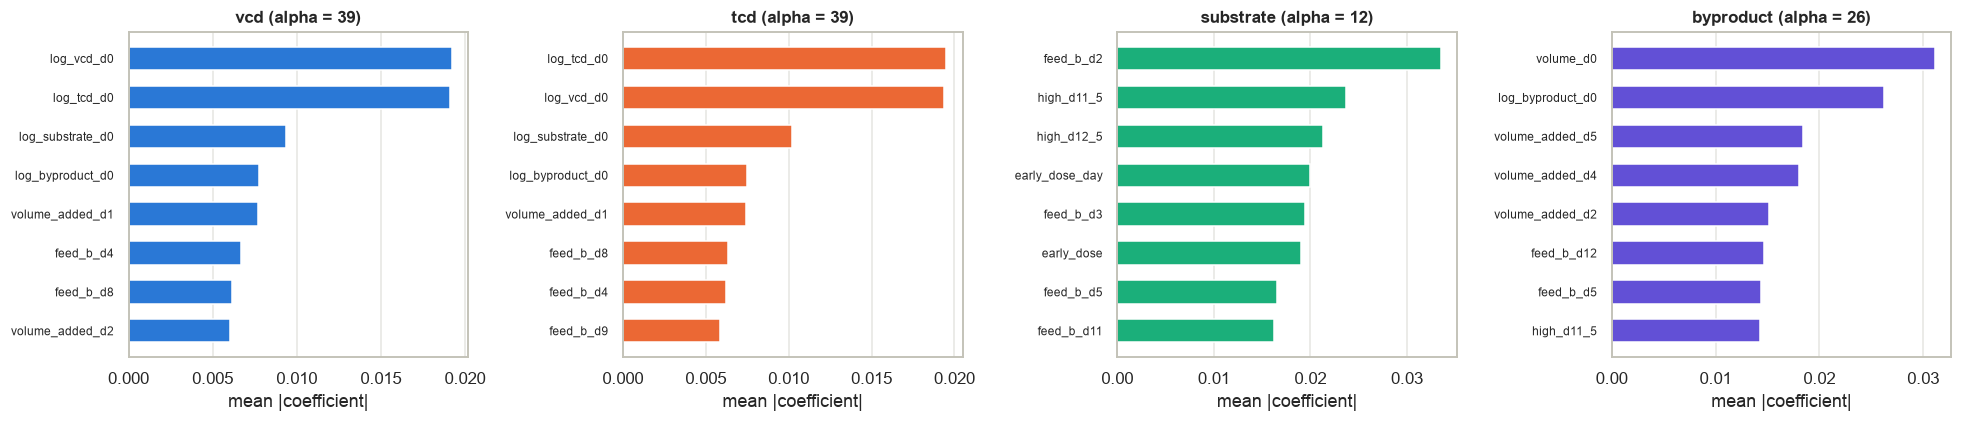

In [12]:
r_all = RidgeLogRatio().fit(TRAIN_IDS)
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, v in zip(axes, STATE):
    coef = pd.Series(np.abs(r_all.models[v].coef_).mean(axis=0), index=FEAT.columns).nlargest(8)[::-1]
    ax.barh(coef.index, coef.values, color=VAR_COLORS[v], height=0.6)
    ax.set_title(f"{v} (alpha = {r_all.models[v].alpha_:.0f})"); ax.set_xlabel("mean |coefficient|")
    ax.grid(axis="y", visible=False); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

## 3d. Gaussian process as a third ensemble member

Same targets (log ratio to day 0, days 1-13) and the same 36 features as ridge and boosting, standardised on the training fold.
One `GaussianProcessRegressor` per variable, predicting all 13 days at once.

**Kernel:** `C·DotProduct + C·RBF + WhiteKernel`

- **linear part:** the ridge-like trend;
- **RBF part:** smooth non-linear corrections between similar batches;
- **white noise:** measurement noise.

Kernel hyperparameters are fitted by maximising the marginal likelihood **inside each training fold** (2 optimiser restarts),
so nothing is tuned on the held-out batches.

Kernels tried in a scratch run on the team folds (pooled mean MAPE, GP alone):

| Kernel | All 36 features | 8 PCA components | Day 0 + `feed_substrate` flags |
|---|---|---|---|
| RBF + noise | 9.17 | 9.63 | 9.31 |
| Matérn 2.5 + noise | 9.16 | 9.51 | 9.36 |
| **linear + RBF + noise** | **8.69** | 9.20 | 9.14 |
| ARD RBF + noise | - | - | 9.19 |

An isotropic RBF on 36 dimensions with ~40 batches can't tell relevant features from irrelevant ones. Adding the linear
term fixes most of that.

In [13]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, DotProduct, ConstantKernel


class GPLogRatio(LogRatioModel):
    def __init__(self, n_restarts=2):
        self.n_restarts = n_restarts

    def _kernel(self, d):
        return (ConstantKernel(0.1) * DotProduct(1.0) + ConstantKernel(1.0) * RBF(length_scale=np.sqrt(d))
                + WhiteKernel(0.5))

    def fit(self, batch_ids):
        ids = list(batch_ids)
        self.scaler = StandardScaler().fit(self.feat.loc[ids])
        X = self.scaler.transform(self.feat.loc[ids])
        self.models = {v: GaussianProcessRegressor(self._kernel(X.shape[1]), normalize_y=True,
                                                   n_restarts_optimizer=self.n_restarts, random_state=0)
                          .fit(X, self._targets(ids, v).values) for v in STATE}
        return self

    def _predict_logratio(self, ids):
        X = self.scaler.transform(self.feat.loc[ids])
        return {v: pd.DataFrame(m.predict(X), index=ids, columns=DAYS) for v, m in self.models.items()}


import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)    # bounds warnings from the kernel optimiser

display(cross_validate(GPLogRatio, "Gaussian process (log ratio)"))
display(cross_validate(Ensemble, "ensemble: ridge + boosting + GP",
                       members=(RidgeLogRatio, BoostingLogRatio, GPLogRatio)))

Gaussian process (log ratio): 1s


,vcd,tcd,substrate,byproduct,mean
mean,7.69,7.65,9.08,10.38,8.7
std,1.28,1.38,1.47,1.58,0.8


ensemble: ridge + boosting + GP: 8s


,vcd,tcd,substrate,byproduct,mean
mean,7.47,7.43,9.03,9.79,8.43
std,1.29,1.37,1.57,1.45,0.72


In [14]:
# How similar are the members? Correlation of their out-of-fold errors (log scale), pooled over variables
members = ["ridge (log ratio)", "gradient boosting (log ratio)", "Gaussian process (log ratio)"]
err = pd.DataFrame({m: np.concatenate([np.log(OOF[m][f"{v}_pred"] / OOF[m][v]).values for v in STATE]) for m in members})
err.columns = ["ridge", "boosting", "GP"]
fitted_gp = GPLogRatio().fit(TRAIN_IDS)
print("GP kernels fitted on all 49 batches:")
for v, m in fitted_gp.models.items():
    print(f"  {v:9s} {m.kernel_}")
err.corr().round(2)

GP kernels fitted on all 49 batches:
  vcd       0.12**2 * DotProduct(sigma_0=0.000404) + 0.00389**2 * RBF(length_scale=0.107) + WhiteKernel(noise_level=0.65)
  tcd       0.121**2 * DotProduct(sigma_0=0.000477) + 0.00316**2 * RBF(length_scale=0.08) + WhiteKernel(noise_level=0.644)
  substrate 0.145**2 * DotProduct(sigma_0=0.000326) + 0.0193**2 * RBF(length_scale=0.0146) + WhiteKernel(noise_level=0.461)
  byproduct 0.149**2 * DotProduct(sigma_0=5.9e-05) + 0.00316**2 * RBF(length_scale=0.594) + WhiteKernel(noise_level=0.457)


,ridge,boosting,GP
ridge,1.00,0.86,1.00
boosting,0.86,1.00,0.87
GP,1.00,0.87,1.00


**Reading this:** the GP turns into ridge. The marginal likelihood shrinks the RBF part to almost nothing
(its amplitude is ~0.003-0.02 against ~0.12-0.15 for the linear part). What's left is a Bayesian linear model, so its
out-of-fold errors correlate **1.00** with ridge's. As a third member it adds no new information: the ensemble just counts
the linear view twice and boosting once, and scores slightly worse (8.43 vs 8.39 on the team folds).

With ~40 training batches, the data don't support a smooth non-linear surface over 36 features. An ensemble only gains from
members that make *different* mistakes, so the 2-member ensemble stays the submission model.

## 3e. Targeting substrate and byproduct: `feed_c` per-day features and substrate caps

Substrate and byproduct are where we trail the leaderboard. Two ideas aimed at them:

1. **`feed_c` per-day features.** The small `feed_c` doses come at irregular times and might be triggered by the culture (e.g. pH,
   which byproduct affects). So far the models only see the total count. Here they also get the count of small doses
   in the interval before each daily sample (days 1-13), either per day or cumulative.
2. **Substrate caps.** `feed_substrate` follows exact threshold rules on the substrate measured just before it
   (`data_overview` section 5b). The feed events are known for test batches, so each rule is a hard bound on a hidden value:

| Sample | Dose that follows | Implies |
|---|---|---|
| day 7, 8 or 9 | early dose | substrate below ~1.95 |
| day 7, 8 or 9 | no dose | substrate above ~1.95 |
| day 11 or 12 | high dose (~0.095) | substrate below ~0.965 |
| day 11 or 12 | low dose (~0.064) | substrate above ~0.965 |

   In the training data these rules hold for every batch without exception: on days 7-9 triggered ≤ 1.91 vs
   not triggered ≥ 1.99, on days 11-12 high ≤ 0.96 vs low ≥ 0.97. The caps clip any predicted substrate that breaks a rule to the
   threshold. The thresholds are re-learned on each training fold (midpoint between the two groups).

In [15]:
# --- 1. feed_c small doses per day (interval before each day's sample) and cumulative ---
fc_ev = raw.dropna(subset=["feed_c"])
small = fc_ev[fc_ev.feed_c < 0.0013].assign(day=lambda d: np.floor(d.elapsed_time).astype(int) + 1)
fc_cnt = small.pivot_table(index="batch_id", columns="day", values="feed_c", aggfunc="size") \
              .reindex(index=FEAT.index, columns=DAYS).fillna(0)
FEAT_FC_DAY = FEAT.join(fc_cnt.add_prefix("feed_c_small_d"))
FEAT_FC_CUM = FEAT.join(fc_cnt.cumsum(axis=1).add_prefix("feed_c_small_cum_d"))

class RidgeFCDay(RidgeLogRatio):       feat = FEAT_FC_DAY
class BoostingFCDay(BoostingLogRatio): feat = FEAT_FC_DAY
class RidgeFCCum(RidgeLogRatio):       feat = FEAT_FC_CUM
class BoostingFCCum(BoostingLogRatio): feat = FEAT_FC_CUM

display(cross_validate(Ensemble, "ensemble + feed_c per day", members=(RidgeFCDay, BoostingFCDay)))
display(cross_validate(Ensemble, "ensemble + feed_c cumulative", members=(RidgeFCCum, BoostingFCCum)))

ensemble + feed_c per day: 7s


,vcd,tcd,substrate,byproduct,mean
mean,7.51,7.49,9.33,9.78,8.53
std,1.28,1.36,1.55,1.38,0.68


ensemble + feed_c cumulative: 6s


,vcd,tcd,substrate,byproduct,mean
mean,7.49,7.44,9.14,9.62,8.42
std,1.25,1.31,1.62,1.47,0.68


In [16]:
# --- 2. substrate caps from the feed_substrate controller ---
CAP_DAYS = {7: "early", 8: "early", 9: "early", 11: "late", 12: "late"}

def substrate_triggers():
    """For every sample on days 7-9 and 11-12 (incl. hidden test samples): did a 'below threshold' dose follow within 0.8 d?"""
    fs_ev = raw.dropna(subset=["feed_substrate"])
    samp = raw[raw.vcd.notna() | raw.to_predict].assign(day=lambda d: d.elapsed_time.round().astype(int))
    rows = []
    for _, s in samp[samp.day.isin(list(CAP_DAYS))].iterrows():
        ev = fs_ev[(fs_ev.batch_id == s.batch_id) & (fs_ev.elapsed_time > s.elapsed_time) & (fs_ev.elapsed_time < s.elapsed_time + 0.8)]
        dose = ev.feed_substrate.iloc[0] if len(ev) else 0.0
        below = dose > 0.08 if s.day >= 11 else dose > 0                # late: high dose; early: any dose
        rows.append({"batch_id": s.batch_id, "day": s.day, "below": bool(below)})
    return pd.DataFrame(rows).set_index(["batch_id", "day"]).below

TRIGGERS = substrate_triggers()


class SubstrateCaps:
    """Wraps any model and clips its substrate predictions to the bounds implied by feed_substrate."""
    def __init__(self, base=Ensemble, **base_kwargs):
        self.base, self.base_kwargs = base, base_kwargs

    def fit(self, batch_ids):
        self.model = self.base(**self.base_kwargs).fit(batch_ids)
        t = TARGETS[TARGETS.batch_id.isin(batch_ids)].assign(day=lambda d: d.elapsed_time.round().astype(int))
        t = t[t.day.isin(list(CAP_DAYS))].set_index(["batch_id", "day"]).substrate
        below = TRIGGERS.loc[t.index]
        self.thresholds = {}
        for grp in ["early", "late"]:
            m = t.index.get_level_values("day").map(CAP_DAYS) == grp
            self.thresholds[grp] = (t[m & below.values].max() + t[m & ~below.values].min()) / 2
        return self

    def predict(self, batch_ids, query):
        pred = self.model.predict(batch_ids, query).reset_index(drop=True)
        day = query.elapsed_time.round().astype(int).values
        self.n_capped = 0
        for i, (b, d) in enumerate(zip(query.batch_id.values, day)):
            if d not in CAP_DAYS:
                continue
            thr, below = self.thresholds[CAP_DAYS[d]], TRIGGERS.loc[(b, d)]
            if (below and pred.at[i, "substrate"] > thr) or (not below and pred.at[i, "substrate"] < thr):
                pred.at[i, "substrate"] = thr
                self.n_capped += 1
        return pred

display(cross_validate(SubstrateCaps, "ensemble + substrate caps"))
n = sum(m.n_capped for m in MODELS["ensemble + substrate caps"])
print(f"caps changed {n} of {len(TARGETS[TARGETS.elapsed_time.round().isin(list(CAP_DAYS))])} constrained held-out predictions; "
      f"thresholds learned on all 49: {SubstrateCaps().fit(TRAIN_IDS).thresholds}")

ensemble + substrate caps: 7s


,vcd,tcd,substrate,byproduct,mean
mean,7.43,7.40,8.83,9.63,8.32
std,1.28,1.37,1.58,1.44,0.68


caps changed 16 of 245 constrained held-out predictions; thresholds learned on all 49: {'early': np.float64(1.9507900183545739), 'late': np.float64(0.9666116727012464)}


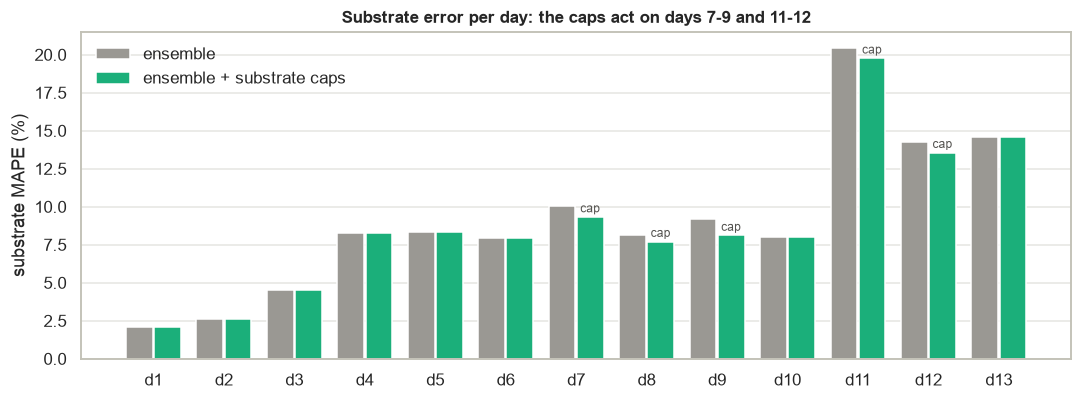

day,1,2,3,4,5,6,7,8,9,10,11,12,13
ensemble,2.08,2.64,4.52,8.27,8.36,7.96,10.04,8.15,9.21,8.03,20.47,14.27,14.55
ensemble + caps,2.08,2.64,4.52,8.27,8.36,7.96,9.32,7.71,8.11,8.03,19.76,13.56,14.55


In [17]:
# Where do the caps act? Substrate MAPE per day, ensemble with vs without caps (out-of-fold)
def per_day_mape(name, v="substrate"):
    o = OOF[name].assign(day=lambda d: d.elapsed_time.round().astype(int))
    return ((o[f"{v}_pred"] - o[v]).abs() / o[v] * 100).groupby(o.day).mean()

cmp = pd.DataFrame({"ensemble": per_day_mape("ensemble: ridge + boosting"),
                    "ensemble + caps": per_day_mape("ensemble + substrate caps")})
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(cmp))
ax.bar(x - 0.2, cmp["ensemble"], 0.38, color="#9a9893", label="ensemble")
ax.bar(x + 0.2, cmp["ensemble + caps"], 0.38, color=VAR_COLORS["substrate"], label="ensemble + substrate caps")
for d in CAP_DAYS:
    ax.annotate("cap", (list(cmp.index).index(d) + 0.2, cmp.loc[d, "ensemble + caps"]), xytext=(0, 3),
                textcoords="offset points", ha="center", fontsize=8, color="#52514e")
ax.set_xticks(x, [f"d{d}" for d in cmp.index]); ax.set_ylabel("substrate MAPE (%)")
ax.set_title("Substrate error per day: the caps act on days 7-9 and 11-12")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
cmp.T.round(2)

**Reading this:**

- **The caps help, at no risk.** They only touch predictions that break a rule that holds without exception in the training
  data, and they improve substrate on the capped days. The wrapper works around any model (`SubstrateCaps(base=...)`).
- **The `feed_c` per-day counts don't help.** Per day they make the ensemble worse, and cumulative counts are neutral. Whatever
  triggers the small doses isn't something these four targets track closely enough. So the counts stay out of the submission model.

## 3f. Volume shortfall: a hidden signal for substrate and byproduct

**Why look here.** After the caps, the substrate and byproduct errors are almost unbiased (median signed error ≈ 0 on every day).
So the models get the average shape right and miss batch-specific deviations. Extra mechanistic detail can't fix that without
extra *information* about each batch. Three attempts in a scratch run all failed to beat 8.31 on the team folds:
median (L1) loss 8.40, chained predicted-VCD integral 8.44, ODE predictions as features 8.38.

**The signal.** Recorded volume is an allowed input (it's given at every test timestamp). The feeds are volumes, so the expected
volume at each sample is *start volume + all recorded feeds so far*. The measured volume falls short of that, by about 0.43 at day 13.
The size of the shortfall differs between batches, and it tracks byproduct closely on every day (below).

**A possible mechanism (hypothesis):** pH control adding base that isn't fully recorded in `feed_c`. More byproduct (acid) would mean
more base, so more volume than the recorded feeds explain, i.e. a smaller shortfall.

**Features:** `volume_shortfall_d1 … d13` = measured volume − (day-0 volume + cumulative recorded feeds), at each daily sample.
They go to the **substrate and byproduct** models only. For VCD/TCD they add noise (scratch run: VCD 7.41 → 7.54).

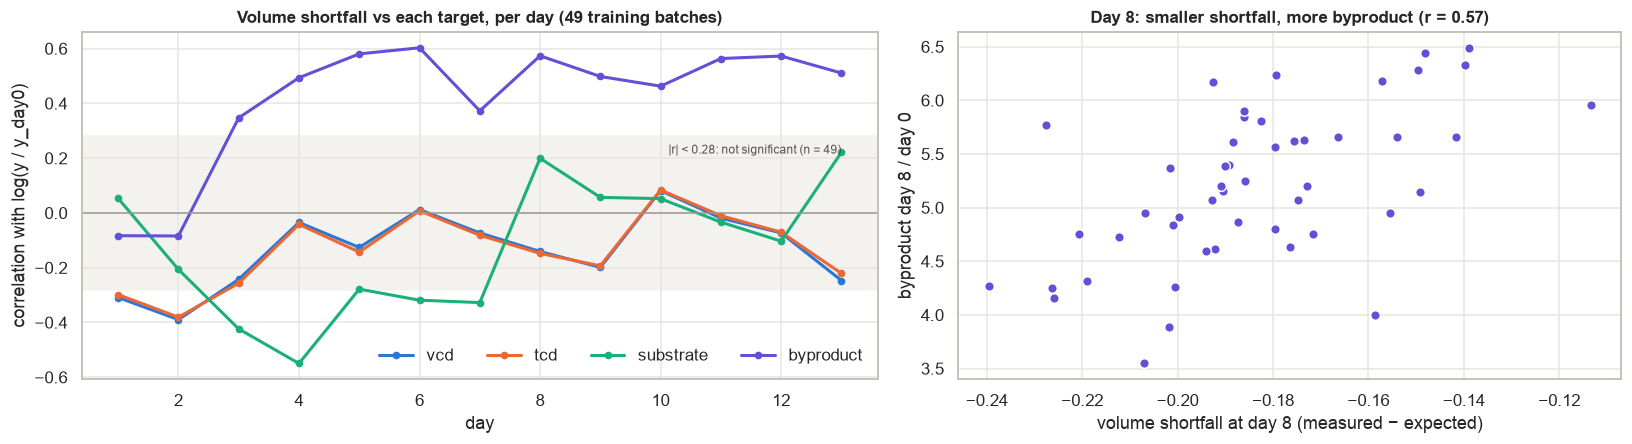

,1,2,3,4,5,6,7,8,9,10,11,12,13
vcd,-0.31,-0.39,-0.24,-0.03,-0.13,0.01,-0.07,-0.14,-0.20,0.08,-0.02,-0.07,-0.25
tcd,-0.30,-0.38,-0.26,-0.04,-0.14,0.01,-0.08,-0.15,-0.19,0.08,-0.01,-0.07,-0.22
substrate,0.05,-0.21,-0.42,-0.55,-0.28,-0.32,-0.33,0.20,0.06,0.05,-0.03,-0.10,0.22
byproduct,-0.08,-0.08,0.35,0.49,0.58,0.60,0.37,0.57,0.50,0.46,0.56,0.57,0.51


In [18]:
r_sorted = raw.sort_values(["batch_id", "elapsed_time"]).copy()
feed_cols = ["feed_substrate", "feed_b", "feed_c", "feed_d"]
r_sorted["cum_feed"] = r_sorted[feed_cols].fillna(0).groupby(r_sorted.batch_id).cumsum().sum(axis=1)
smp = r_sorted[r_sorted.volume.notna()].assign(day=lambda d: d.elapsed_time.round().astype(int))
smp["shortfall"] = smp.volume - (smp.groupby("batch_id").volume.transform("first") + smp.cum_feed)
SHORTFALL = smp.pivot_table(index="batch_id", columns="day", values="shortfall").reindex(index=FEAT.index, columns=DAYS)
assert SHORTFALL.notna().all().all(), "volume is known at every daily sample, test batches included"
FEAT_VS = FEAT.join(SHORTFALL.add_prefix("volume_shortfall_d"))

# How strongly does the shortfall track each target? (training batches, per day)
lr_true = {v: np.log(TARGETS.assign(day=lambda d: d.elapsed_time.round().astype(int))
                     .pivot_table(index="batch_id", columns="day", values=v)).sub(FEAT.loc[TRAIN_IDS, f"log_{v}_d0"], axis=0)
           for v in STATE}
corr = pd.DataFrame({v: [np.corrcoef(SHORTFALL.loc[TRAIN_IDS, d], lr_true[v].loc[TRAIN_IDS, d])[0, 1] for d in DAYS] for v in STATE},
                    index=DAYS)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
for v in STATE:
    ax.plot(corr.index, corr[v], marker="o", ms=4, color=VAR_COLORS[v], label=v)
ax.axhline(0, color="#9a9893", linewidth=1)
ax.axhspan(-0.28, 0.28, color="#f3f2ef", zorder=0)
ax.text(13, 0.25, "|r| < 0.28: not significant (n = 49)", ha="right", va="top", fontsize=8, color="#52514e")
ax.set_xlabel("day"); ax.set_ylabel("correlation with log(y / y_day0)")
ax.set_title("Volume shortfall vs each target, per day (49 training batches)"); ax.legend(frameon=False, ncol=4)

ax = axes[1]
d = 8
ax.scatter(SHORTFALL.loc[TRAIN_IDS, d], np.exp(lr_true["byproduct"].loc[TRAIN_IDS, d]), s=40, color=VAR_COLORS["byproduct"],
           edgecolor="white", linewidth=1)
ax.set_xlabel(f"volume shortfall at day {d} (measured − expected)"); ax.set_ylabel(f"byproduct day {d} / day 0")
ax.set_title(f"Day {d}: smaller shortfall, more byproduct (r = {corr.loc[d, 'byproduct']:.2f})")
plt.tight_layout(); plt.show()
corr.T.round(2)

In [19]:
class RidgeVS(RidgeLogRatio):       feat = FEAT_VS
class BoostingVS(BoostingLogRatio): feat = FEAT_VS


class SplitEnsemble:
    """VCD/TCD from the standard ensemble; substrate/byproduct from the ensemble with volume-shortfall features."""
    def fit(self, batch_ids):
        self.cells = Ensemble().fit(batch_ids)
        self.chem = Ensemble(members=(RidgeVS, BoostingVS)).fit(batch_ids)
        return self

    def predict(self, batch_ids, query):
        a = self.cells.predict(batch_ids, query).reset_index(drop=True)
        b = self.chem.predict(batch_ids, query).reset_index(drop=True)
        return pd.DataFrame({"vcd": a.vcd, "tcd": a.tcd, "substrate": b.substrate, "byproduct": b.byproduct})


display(cross_validate(SubstrateCaps, "ensemble + caps + volume shortfall", base=SplitEnsemble))

ensemble + caps + volume shortfall: 13s


,vcd,tcd,substrate,byproduct,mean
mean,7.43,7.40,8.60,9.02,8.11
std,1.28,1.37,1.47,2.12,0.63


**Reading this:** the shortfall is the first input since the `feed_substrate` caps that moves substrate and byproduct. The scratch run
found the same gain on the stratified split (8.30 → 8.10), and section 4b checks it again on both splits. The submission
cell picks this model if it has the lowest cross-validated mean MAPE.

## 4. Compare models

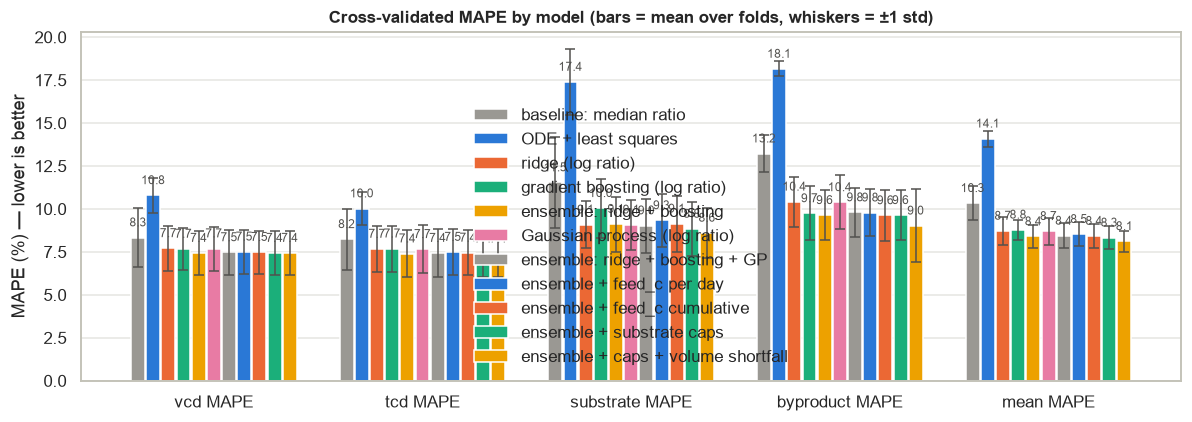

,vcd,tcd,substrate,byproduct,mean
baseline: median ratio,8.33,8.23,11.54,13.22,10.33
ODE + least squares,10.79,10.02,17.39,18.15,14.09
ridge (log ratio),7.71,7.67,9.08,10.42,8.72
gradient boosting (log ratio),7.67,7.69,10.04,9.74,8.78
ensemble: ridge + boosting,7.43,7.40,9.12,9.63,8.39
Gaussian process (log ratio),7.69,7.65,9.08,10.38,8.70
ensemble: ridge + boosting + GP,7.47,7.43,9.03,9.79,8.43
ensemble + feed_c per day,7.51,7.49,9.33,9.78,8.53
ensemble + feed_c cumulative,7.49,7.44,9.14,9.62,8.42
ensemble + substrate caps,7.43,7.40,8.83,9.63,8.32


In [20]:
summary = pd.concat({name: r[STATE + ["mean"]].mean() for name, r in RESULTS.items()}, axis=1).T
spread = pd.concat({name: r[STATE + ["mean"]].std() for name, r in RESULTS.items()}, axis=1).T

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.8 / len(summary)
cols = STATE + ["mean"]
palette = ["#9a9893", "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
for i, (name, row) in enumerate(summary.iterrows()):
    x = np.arange(len(cols)) + (i - (len(summary) - 1) / 2) * width
    ax.bar(x, row[cols], width * 0.92, yerr=spread.loc[name, cols], capsize=3, color=palette[i % len(palette)],
           label=name, error_kw={"elinewidth": 1, "ecolor": "#52514e"})
    for xi, v in zip(x, row[cols]):
        ax.text(xi, v + 0.5, f"{v:.1f}", ha="center", va="bottom", fontsize=8, color="#52514e")
ax.set_xticks(range(len(cols)), [c + " MAPE" for c in cols]); ax.set_ylabel("MAPE (%) — lower is better")
ax.set_title("Cross-validated MAPE by model (bars = mean over folds, whiskers = ±1 std)")
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
summary.round(2)

**Ranking:** the data-driven models (sections 3c-3f) are best. The current leader is the ridge + boosting ensemble with substrate caps
and volume-shortfall features.
The ODE model in its current form is *worse* than even the median-ratio baseline. Basin hopping
lands in the same minimum, so this isn't an optimisation problem. It's the model **structure**. The trajectory plots below
show where it goes wrong:

- **VCD peak too low:** the density limit `1/(1 + (Xv/Xmax)^4)` stops growth too early (Xmax fits to ~21),
  so peaks of 30-39 are missed.
- **Substrate too high on days 2-3:** early consumption is too slow.
- **Parameters at their bounds** (`Ks`, `kd1`, ...) mean some terms aren't supported by the data and could be dropped or reshaped.

The baseline beats the ODE because all batches follow almost the same shape, and per-day medians capture that shape exactly.
The data-driven models start from that same idea (a log ratio to day 0) and add each batch's day-0 values and feeds on top.
The ODE could still be useful as an extra input to them (see the last section).

### Where does the error come from?

MAPE weighs every sample equally in *relative* terms, so days with small true values (late substrate, late byproduct)
can dominate. This shows the out-of-fold MAPE per day for the ODE model.

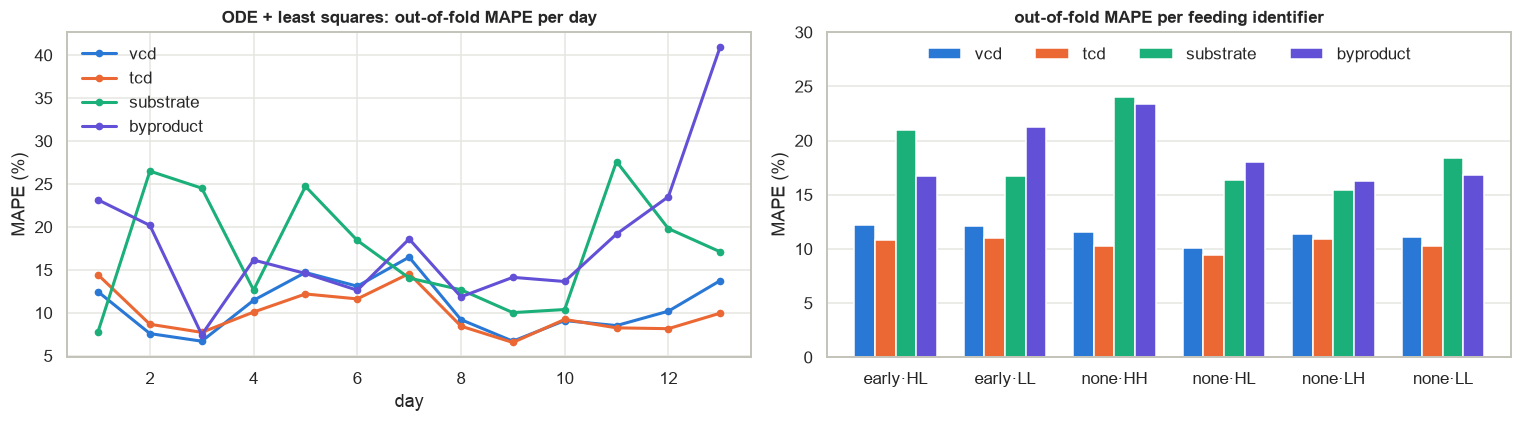

In [21]:
name = "ODE + least squares"
o = OOF[name].assign(day=lambda d: d.elapsed_time.round().astype(int))
per_day = pd.DataFrame({v: (o[f"{v}_pred"] - o[v]).abs().div(o[v].abs()).groupby(o.day).mean() * 100 for v in STATE})

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for v in STATE:
    axes[0].plot(per_day.index, per_day[v], marker="o", ms=4, color=VAR_COLORS[v], label=v)
axes[0].set_xlabel("day"); axes[0].set_ylabel("MAPE (%)"); axes[0].set_title(f"{name}: out-of-fold MAPE per day")
axes[0].legend(frameon=False)

reg = o.join(REGIMEN, on="batch_id")
per_reg = pd.DataFrame({v: (reg[f"{v}_pred"] - reg[v]).abs().div(reg[v].abs()).groupby(reg.regimen).mean() * 100 for v in STATE})
per_reg.plot.bar(ax=axes[1], color=[VAR_COLORS[v] for v in STATE], width=0.75, edgecolor="white")
axes[1].set_title("out-of-fold MAPE per feeding identifier"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=0)
axes[1].set_ylim(0, per_reg.values.max() * 1.25); axes[1].set_ylabel("MAPE (%)")
axes[1].legend(frameon=False, ncol=4, loc="upper center"); axes[1].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

### Predicted vs observed trajectories (out-of-fold)

Six validation batches: dots are measurements, lines are the ODE model's predictions made from day 0 + feeds only.

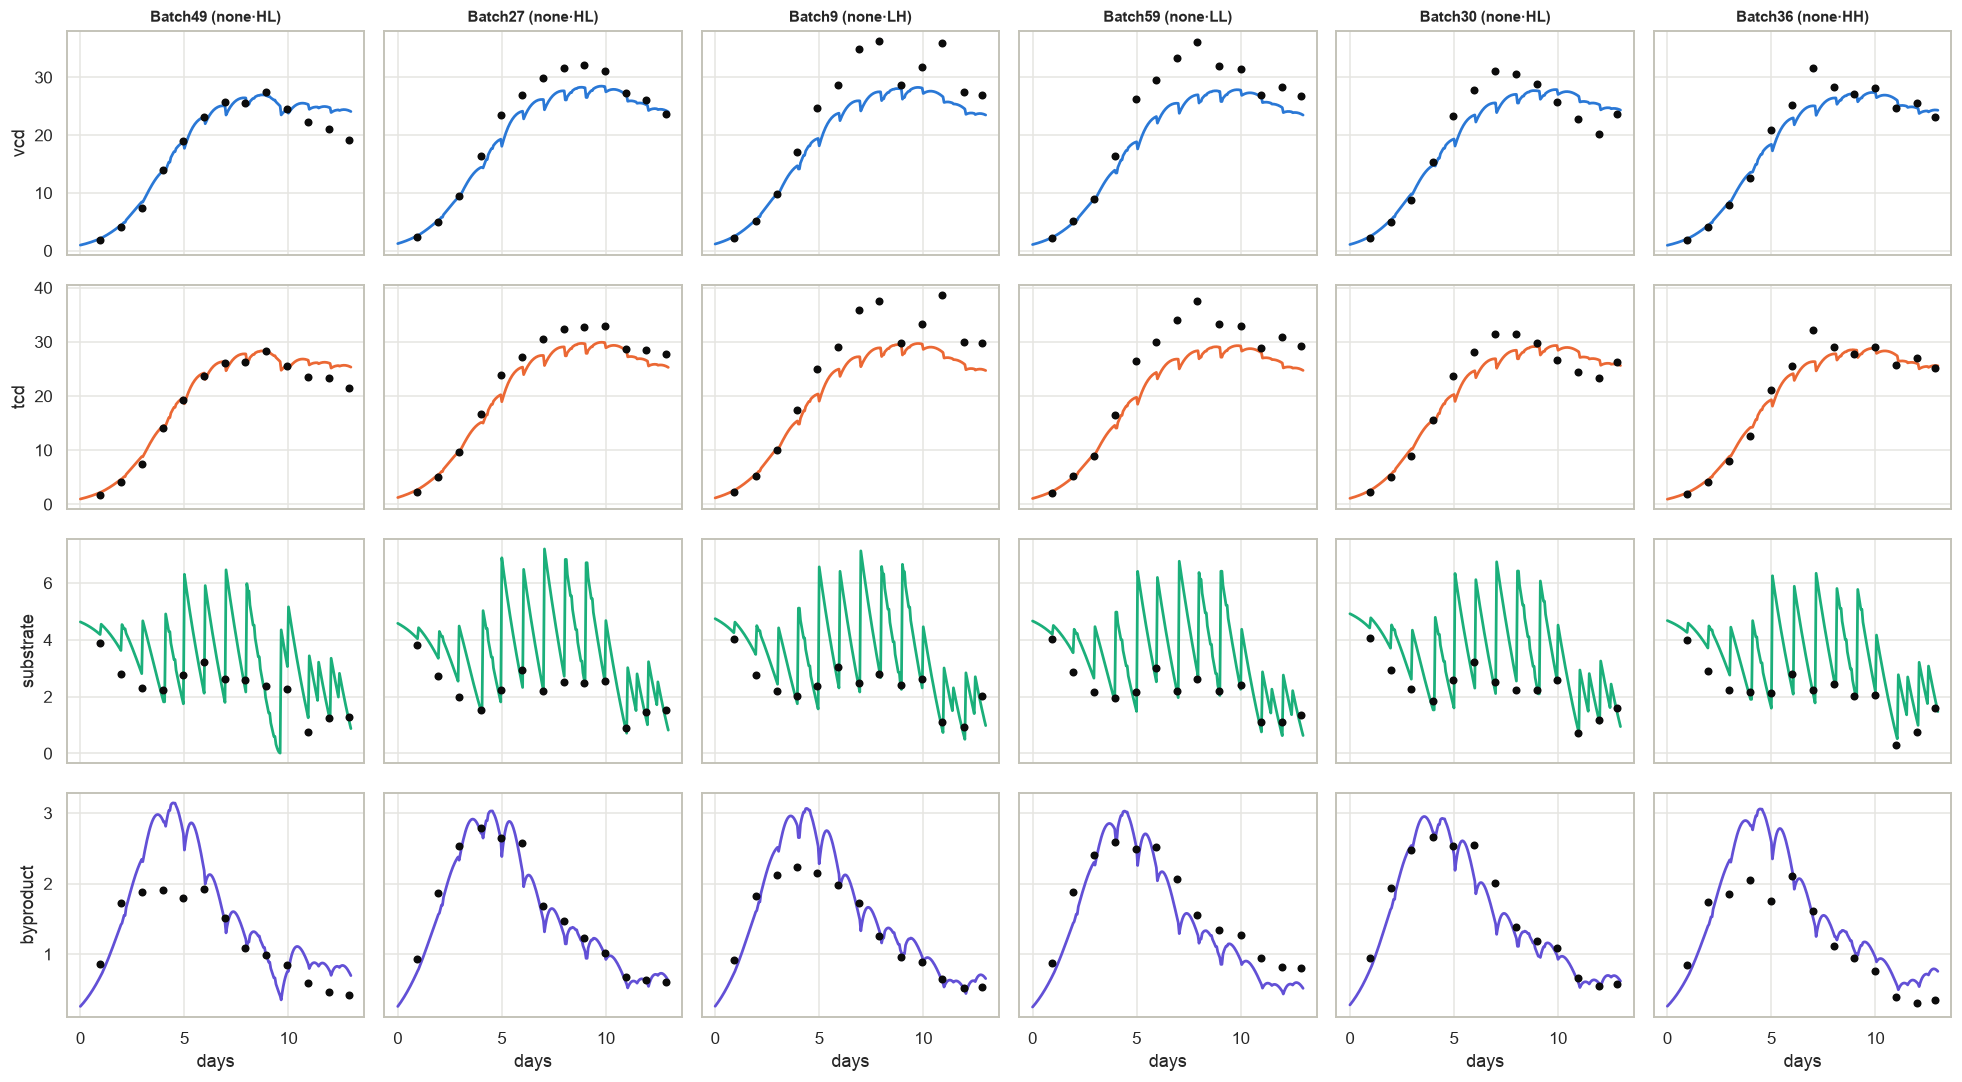

In [22]:
show = OOF[name].batch_id.drop_duplicates().sample(6, random_state=1).tolist()
fig, axes = plt.subplots(len(STATE), len(show), figsize=(18, 10), sharex=True, sharey="row")
for j, b in enumerate(show):
    fold = OOF[name].loc[OOF[name].batch_id == b, "fold"].iloc[0]
    model = MODELS[name][fold]                            # the model that never saw this batch
    q = pd.DataFrame({"batch_id": b, "elapsed_time": GRID[GRID <= 13]})
    curve = model.predict([b], q)
    pts = OOF[name][OOF[name].batch_id == b]
    for i, v in enumerate(STATE):
        ax = axes[i, j]
        ax.plot(q.elapsed_time, curve[v], color=VAR_COLORS[v], linewidth=1.8)
        ax.scatter(pts.elapsed_time, pts[v], s=18, color="#0b0b0b", zorder=3)
        if i == 0: ax.set_title(f"{b} ({REGIMEN[b]})", fontsize=10)
        if j == 0: ax.set_ylabel(v)
        if i == len(STATE) - 1: ax.set_xlabel("days")
plt.tight_layout(); plt.show()

## 4b. Alternative split: stratified by feeding identifier

The team split was drawn at random (seed 42), so feeding groups ended up unevenly spread:

- fold 4 holds out 8 `none·HL` batches and no `LL` batch at all;
- fold 1 holds out 2 of the 3 `early·HL` batches, so its training folds barely see that pattern.

**Proposed split:** `StratifiedKFold(5, shuffle=True, random_state=42)` on the feeding identifier. Every fold gets
5-6 `none·HL`, 1-2 `none·LL`, one `none·LH`, and at most one of each rare group. Fold sizes stay 10/10/10/10/9.

Three scores are reported per split:

- **per-fold mean:** average of the five fold MAPEs (what sections 3-4 show);
- **pooled:** MAPE over all 637 held-out points at once (the team's Protocol A convention);
- **test-weighted:** pooled, but each batch is reweighted so the feeding groups appear in the **same proportions as in
  the 12 test batches** (5 `none·HL`, 3 `early·LL`, 2 `none·LH`, 2 `none·LL`; the groups absent from test get weight 0).
  This is the closest estimate of the leaderboard score.

In [23]:
ids = np.array(TRAIN_IDS)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
STRAT_FOLDS = [(list(ids[tr]), list(ids[va])) for tr, va in skf.split(ids, REGIMEN.loc[ids])]

def composition(folds):
    return pd.DataFrame({f"fold {k + 1}": REGIMEN.loc[va].value_counts() for k, (_, va) in enumerate(folds)}).fillna(0).astype(int)

comp = pd.concat({"team split": composition(TEAM_FOLDS), "stratified split": composition(STRAT_FOLDS)}, axis=1)
comp.insert(0, ("", "test set"), REGIMEN.loc[TEST_IDS].value_counts().reindex(comp.index).fillna(0).astype(int))
comp.insert(0, ("", "train (49)"), REGIMEN.loc[TRAIN_IDS].value_counts().reindex(comp.index))
print("Held-out stratified folds:")
for k, (_, va) in enumerate(STRAT_FOLDS):
    print(f"  fold {k + 1} (n={len(va)}): {', '.join(sorted(va, key=lambda b: int(b[5:])))}")
comp

Held-out stratified folds:
  fold 1 (n=10): Batch3, Batch7, Batch10, Batch13, Batch19, Batch21, Batch22, Batch26, Batch27, Batch34
  fold 2 (n=10): Batch1, Batch9, Batch11, Batch16, Batch17, Batch49, Batch50, Batch51, Batch52, Batch61
  fold 3 (n=10): Batch15, Batch18, Batch23, Batch25, Batch39, Batch41, Batch44, Batch53, Batch55, Batch59
  fold 4 (n=10): Batch2, Batch4, Batch28, Batch30, Batch33, Batch37, Batch42, Batch46, Batch47, Batch58
  fold 5 (n=9): Batch8, Batch14, Batch20, Batch29, Batch31, Batch36, Batch38, Batch43, Batch45


/opt/homebrew/Caskroom/miniforge/base/envs/hackathon/lib/python3.15/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(


team split                              \
         train (49) test set     fold 1 fold 2 fold 3 fold 4 fold 5   
regimen                                                               
early·HL          3        0          2      0      0      0      1   
early·LL          4        3          0      2      1      0      1   
none·HH           3        0          1      1      0      0      1   
none·HL          26        5          4      6      6      8      2   
none·LH           5        2          1      1      0      2      1   
none·LL           8        2          2      0      3      0      3   

         stratified split                              
                   fold 1 fold 2 fold 3 fold 4 fold 5  
regimen                                                
early·HL                0      0      1      1      1  
early·LL                1      1      1      1      0  
none·HH                 1      1      0      0      1  
none·HL                 6      5      5      5      5  
none·LH                 1      1      1      1      1  
none·LL                 1      2      2      2      1

In [24]:
test_share = REGIMEN.loc[TEST_IDS].value_counts(normalize=True)
train_share = REGIMEN.loc[TRAIN_IDS].value_counts(normalize=True)
BATCH_W = (REGIMEN.map(test_share) / REGIMEN.map(train_share)).fillna(0)   # weight per batch

def pooled_scores(oof, weighted=False):
    w = oof.batch_id.map(BATCH_W).values if weighted else np.ones(len(oof))
    out = {v: float(np.sum(w * np.abs(oof[f"{v}_pred"] - oof[v]) / np.abs(oof[v])) / w.sum() * 100) for v in STATE}
    out["mean"] = float(np.mean(list(out.values())))
    return out

COMPARE = [(MedianRatioBaseline, "baseline: median ratio"), (ODELeastSquares, "ODE + least squares"),
           (RidgeLogRatio, "ridge (log ratio)"), (BoostingLogRatio, "gradient boosting (log ratio)"),
           (Ensemble, "ensemble: ridge + boosting"), (GPLogRatio, "Gaussian process (log ratio)"),
           (Ensemble, "ensemble: ridge + boosting + GP"), (SubstrateCaps, "ensemble + substrate caps"),
           (SubstrateCaps, "ensemble + caps + volume shortfall")]
for model_cls, base in COMPARE:
    cross_validate(model_cls, f"{base} | stratified split", folds=STRAT_FOLDS, **SPECS[base][1])

rows = {}
for _, base in COMPARE:
    for split, key in [("team split", base), ("stratified split", f"{base} | stratified split")]:
        rows[(base, split, "per-fold mean")] = RESULTS[key][STATE + ["mean"]].mean().to_dict()
        rows[(base, split, "pooled")] = pooled_scores(OOF[key])
        rows[(base, split, "test-weighted")] = pooled_scores(OOF[key], weighted=True)
split_table = pd.DataFrame(rows).T.round(2)
split_table.index.names = ["model", "split", "score"]
split_table

baseline: median ratio | stratified split: 0s


ODE + least squares | stratified split: 78s
ridge (log ratio) | stratified split: 0s


gradient boosting (log ratio) | stratified split: 6s


ensemble: ridge + boosting | stratified split: 6s


Gaussian process (log ratio) | stratified split: 1s


ensemble: ridge + boosting + GP | stratified split: 8s


ensemble + substrate caps | stratified split: 7s


ensemble + caps + volume shortfall | stratified split: 14s


vcd  \
model                              split            score                  
baseline: median ratio             team split       per-fold mean   8.33   
                                                    pooled          8.31   
                                                    test-weighted   8.24   
                                   stratified split per-fold mean   8.40   
                                                    pooled          8.41   
                                                    test-weighted   8.30   
ODE + least squares                team split       per-fold mean  10.79   
                                                    pooled         10.77   
                                                    test-weighted  10.98   
                                   stratified split per-fold mean  10.77   
                                                    pooled         10.78   
                                                    test-weighted  10.99   
ridge (log ratio)                  team split       per-fold mean   7.71   
                                                    pooled          7.69   
                                                    test-weighted   7.77   
                                   stratified split per-fold mean   7.71   
                                                    pooled          7.71   
                                                    test-weighted   7.93   
gradient boosting (log ratio)      team split       per-fold mean   7.67   
                                                    pooled          7.65   
                                                    test-weighted   7.73   
                                   stratified split per-fold mean   7.60   
                                                    pooled          7.62   
                                                    test-weighted   7.55   
ensemble: ridge + boosting         team split       per-fold mean   7.43   
                                                    pooled          7.41   
                                                    test-weighted   7.50   
                                   stratified split per-fold mean   7.36   
                                                    pooled          7.36   
                                                    test-weighted   7.37   
Gaussian process (log ratio)       team split       per-fold mean   7.69   
                                                    pooled          7.68   
                                                    test-weighted   7.68   
                                   stratified split per-fold mean   7.72   
                                                    pooled          7.73   
                                                    test-weighted   7.83   
ensemble: ridge + boosting + GP    team split       per-fold mean   7.47   
                                                    pooled          7.45   
                                                    test-weighted   7.51   
                                   stratified split per-fold mean   7.41   
                                                    pooled          7.41   
                                                    test-weighted   7.45   
ensemble + substrate caps          team split       per-fold mean   7.43   
                                                    pooled          7.41   
                                                    test-weighted   7.50   
                                   stratified split per-fold mean   7.36   
                                                    pooled          7.36   
                                                    test-weighted   7.37   
ensemble + caps + volume shortfall team split       per-fold mean   7.43   
                                                    pooled          7.41   
                                                    test-weighted   7.50   
                                   strati

In [25]:
fold_sd = pd.DataFrame({
    (base, split): RESULTS[key]["mean"].agg(["min", "max", "std"])
    for _, base in COMPARE
    for split, key in [("team split", base), ("stratified split", f"{base} | stratified split")]
}).T.round(2)
fold_sd.columns = ["best fold", "worst fold", "SD across folds"]
fold_sd

best fold  worst fold  \
baseline: median ratio             team split             9.11       11.38   
                                   stratified split       9.90       10.51   
ODE + least squares                team split            13.59       14.73   
                                   stratified split      13.44       14.96   
ridge (log ratio)                  team split             7.51        9.36   
                                   stratified split       7.90        9.35   
gradient boosting (log ratio)      team split             7.92        9.37   
                                   stratified split       8.36        9.49   
ensemble: ridge + boosting         team split             7.32        9.06   
                                   stratified split       8.16        8.89   
Gaussian process (log ratio)       team split             7.54        9.34   
                                   stratified split       7.96        9.33   
ensemble: ridge + boosting + GP    team split             7.32        9.03   
                                   stratified split       8.05        8.90   
ensemble + substrate caps          team split             7.25        8.96   
                                   stratified split       8.10        8.81   
ensemble + caps + volume shortfall team split             7.12        8.75   
                                   stratified split       7.69        8.46   

                                                     SD across folds  
baseline: median ratio             team split                   0.99  
                                   stratified split             0.25  
ODE + least squares                team split                   0.46  
                                   stratified split             0.57  
ridge (log ratio)                  team split                   0.83  
                                   stratified split             0.54  
gradient boosting (log ratio)      team split                   0.57  
                                   stratified split             0.51  
ensemble: ridge + boosting         team split                   0.69  
                                   stratified split             0.30  
Gaussian process (log ratio)       team split                   0.80  
                                   stratified split             0.51  
ensemble: ridge + boosting + GP    team split                   0.72  
                                   stratified split             0.32  
ensemble + substrate caps          team split                   0.68  
                                   stratified split             0.29  
ensemble + caps + volume shortfall team split                   0.63  
                                   stratified split             0.30

## 5. Submission

Takes the model with the **lowest cross-validated mean MAPE** in `RESULTS`, refits it on all 49 training batches,
and predicts the 12 test batches at the template's time points. The file is written next to this notebook.

In [26]:
best = summary["mean"].idxmin()
model_cls, kwargs = SPECS[best]
final = model_cls(**kwargs).fit(TRAIN_IDS)
q = template[["batch_id", "elapsed_time"]]
sub = q.join(final.predict(sorted(q.batch_id.unique()), q))
# Team submission checks: row count, no gaps, all positive, TCD >= VCD
n_fixed = int((sub.tcd < sub.vcd).sum())
sub["tcd"] = np.maximum(sub.tcd, sub.vcd)
assert len(sub) == len(template) and sub[STATE].notna().all().all()
assert (sub[STATE] > 0).all().all() and (sub.tcd >= sub.vcd).all()
print(f"checks passed: {len(sub)} rows, all positive, TCD >= VCD ({n_fixed} rows raised to VCD)")
import re
slug = re.sub(r"[^a-z0-9]+", "_", best.lower()).strip("_")
out = Path(f"submission_{slug}.csv")
sub[template.columns].to_csv(out, index=False)
print(f"best CV model: {best} ({summary.loc[best, 'mean']:.2f}% mean MAPE) -> wrote {out} ({len(sub)} rows)")
sub.head()

checks passed: 156 rows, all positive, TCD >= VCD (3 rows raised to VCD)
best CV model: ensemble + caps + volume shortfall (8.11% mean MAPE) -> wrote submission_ensemble_caps_volume_shortfall.csv (156 rows)


,batch_id,elapsed_time,vcd,tcd,substrate,byproduct
0,Batch5,0.965972,2.421812,2.447189,3.822557,0.988136
1,Batch5,1.948611,5.474248,5.581816,2.730103,1.938176
2,Batch5,2.940278,10.091599,10.299179,2.046588,2.295968
3,Batch5,3.919444,17.549372,17.877026,1.929735,2.379193
4,Batch5,4.924306,26.550647,26.852659,2.249908,2.371575


## Ideas for the next models

- **Late byproduct:** byproduct on days 11-13 is still the largest single error. Already tried without gain: median (L1) loss,
  chained predicted-VCD integral, ODE predictions as features, `feed_c` per-day counts, `feed_d` amount/timing.
- **Exploit the volume shortfall mechanistically:** if it's unrecorded pH titrant, it measures acid (byproduct) production directly.
  An ODE byproduct equation driven by it might extrapolate better than the regression.
- **Hybrid:** add the ODE's predicted log ratios as extra features to ridge / boosting, so they learn to correct the ODE.
- **A more different third member:** the GP mostly repeats ridge. A member built on other information would add more, e.g. the ODE's predictions or features from the days 10-12 feeds.
- **Predict `tcd` and viability** instead of `tcd` and `vcd`, so TCD ≥ VCD holds by construction.
- **Weighting similar batches:** weight training batches by similarity to the batch being predicted, inside one global model.
  Hard per-cluster models were worse (`data_overview` section 8).